In [8]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

In [24]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers
import pandas as pd

def evaluate_model(y_true, y_pred, scores):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Clf Report": clf_report.strip()
    }

    return result


In [41]:
from tensorflow.keras import layers, Model
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer.primitives import Sampler
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.optimizers import COBYLA
import matplotlib.pyplot as plt
import time

# --------------------------
# 1️⃣ Feature extraction from QAE
# --------------------------
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer.primitives import Sampler
from qiskit_machine_learning.neural_networks import SamplerQNN
from tqdm import tqdm

def get_latent_vectors(ae_circ, trained_params, weight_params, qnn, data, num_latent, num_trash, encoding_fn, num_features=8, shots=1024):
    """
    Extract latent vectors from a trained QAE for classical post-processing (NCE / Isolation Forest).

    Parameters
    ----------
    ae_circ : QuantumCircuit
        Trained autoencoder circuit.
    trained_params : list or np.ndarray
        Parameter values obtained from training (COBYLA).
    weight_params : list
        The parameters in the AE that are trainable.
    qnn : SamplerQNN
        QNN wrapper around the AE circuit.
    data : np.ndarray
        Scaled input data (shape [n_samples, n_total_features]).
    num_latent : int
        Number of latent qubits in the AE.
    num_trash : int
        Number of trash qubits in the AE.
    encoding_fn : function
        Function to encode classical data to a quantum circuit (e.g., dense_angle_encoding).
    num_features : int
        Number of classical features to select for encoding (slice of input).

    Returns
    -------
    latent_vectors : np.ndarray
        Array of shape [n_samples, num_latent] with measured probabilities from latent qubits.
    """

    total_qubits = num_latent + 2 * num_trash + 1  # latent + trash + auxiliary
    latent_vectors = []

    # Assign trained parameters
    ae_circ = ae_circ.assign_parameters({p: v for p, v in zip(weight_params, trained_params)})

    for x in tqdm(data, desc="Extracting latent vectors"):
        # 1️⃣ Slice input to match encoder input size
        input_slice = x[:num_features]  # scale already done (0, π)

        # 2️⃣ Encode input
        enc_circ = encoding_fn(input_slice)
        enc_qubits = enc_circ.num_qubits

        # 3️⃣ Compose full circuit
        full_circ = QuantumCircuit(total_qubits, num_latent)  # measure latent qubits
        full_circ.compose(enc_circ, qubits=range(enc_qubits), inplace=True)
        full_circ.compose(ae_circ, inplace=True)

        # 4️⃣ Measure latent qubits
        # for i in range(num_latent):
        #     full_circ.measure(i, i)

        # # 5️⃣ Run circuit
        # job = qnn.sampler.run([full_circ])
        # result = job.result()
        # quasi = result.quasi_dists[0]

        # # 6️⃣ Compute classical probabilities for latent qubits
        # p_vector = np.zeros(num_latent)
        # for bitint, prob in quasi.items():
        #     # Convert integer to binary string, padded to num_latent
        #     bits = np.array([int(b) for b in format(bitint, f'0{num_latent}b')])
        #     p_vector += bits * prob  # expected value per qubit
        
        # latent_vectors.append(p_vector)
        exp_vals = []
        for basis in ["Z", "X", "Y"]:
            circ = full_circ.copy()
            for i in range(num_latent):
                if basis == "X":
                    circ.h(i)  # rotate X -> Z
                elif basis == "Y":
                    circ.sdg(i)
                    circ.h(i)  # rotate Y -> Z
            circ.measure(range(num_latent), range(num_latent))
            
            job = qnn.sampler.run([circ], shots=shots)
            result = job.result()
            counts = result.quasi_dists[0]  # dictionary of bitstring -> prob
            
            # Convert counts to expectation value per qubit
            ev = np.zeros(num_latent)
            for bitstring, prob in counts.items():
                bits = np.array([int(b) for b in format(bitstring, f'0{num_latent}b')])
                ev += (1 - 2*bits) * prob  # |0> → +1, |1> → -1

            exp_vals.extend(ev)

        latent_vectors.append(exp_vals)

    return np.array(latent_vectors)



In [42]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [43]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

reduced_testing_data = testing_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)

reduced_normal_training_data = normal_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)

reduced_validation_data = validation_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_validation_data = scaler.fit_transform(reduced_validation_data)

In [44]:
from qiskit.qpy import load
from qiskit_aer.primitives import Sampler

model_name = "8f_qae_dense_ra2_5k"
model_path = "Models/QAE/First_N/"

with open(f"{model_path + model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits
    
weight_names = np.load(f"{model_path + model_name}/weight_param_names.npy", allow_pickle=True)
weight_params = [p for p in ae.parameters if p.name in weight_names]
trained_params = np.load(f"{model_path + model_name}/trained_parameters.npy")

num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  

dummy_encoding = QuantumCircuit(total_qubits)
qc_full = dummy_encoding.compose(ae)
sampler = Sampler()

qnn = SamplerQNN(
    circuit=qc_full,
    input_params=[],                     # No input parameters — encoding is done externally
    weight_params=weight_params,         # Only train the parameters of the AE
    output_shape=2,                      # Binary outcome (0 or 1 from SWAP test)
    interpret=lambda x: x,               # Identity function, optional
    sampler=sampler
)

# qc_full.draw('mpl')

C:\Users\Rohan\AppData\Local\Temp\ipykernel_25532\1981916388.py:22: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [45]:
latent_vectors = get_latent_vectors(
    ae_circ=ae,
    trained_params=trained_params,
    weight_params=weight_params,
    qnn=qnn,
    data=scaled_normal_training_data[:5000],
    num_latent=num_latent,
    num_trash=num_trash,
    encoding_fn=dense_angle_encoding,
    num_features=8  # slice first 8 features for encoder
)


Extracting latent vectors: 100%|███████████████████████████████████████████████████| 5000/5000 [01:33<00:00, 53.45it/s]


In [46]:
# Extract latent vectors for test data
latent_test = get_latent_vectors(
    ae_circ=ae,
    trained_params=trained_params,
    weight_params=weight_params,
    qnn=qnn,
    data=scaled_testing_data,
    num_latent=num_latent,
    num_trash=num_trash,
    encoding_fn=dense_angle_encoding,
    num_features=8
)


Extracting latent vectors: 100%|███████████████████████████████████████████████| 188967/188967 [44:39<00:00, 70.53it/s]


In [55]:
from sklearn.ensemble import IsolationForest

# Train only on normal latent vectors
iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_forest.fit(latent_vectors)  # shape: (num_samples, num_features)

preds = iso_forest.predict(latent_test)  # -1 = anomaly, 1 = normal
preds = np.where(preds == -1, 1, 0)  # Convert to 0=normal, 1=anomaly

scores = iso_forest.decision_function(latent_test)  # higher = more normal
y_true = np.array(testing_labels).astype(int)[:len(scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=preds,
    scores=scores
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")


Precision: 0.822
Accuracy: 0.127
Recall: 0.049
F1-Score: 0.093
Matrix: TP=8412, FP=1827, FN=163047, TN=15681
AUROC: 0.510
Clf Report: precision    recall  f1-score   support

           0       0.09      0.90      0.16     17508
           1       0.82      0.05      0.09    171459

    accuracy                           0.13    188967
   macro avg       0.45      0.47      0.13    188967
weighted avg       0.75      0.13      0.10    188967


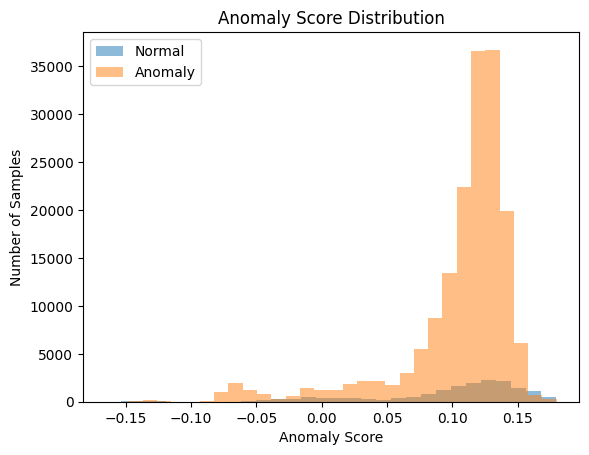

In [56]:
import matplotlib.pyplot as plt
# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()